# ML Lab 09 — Bias, Variance and Imbalanced Data

## Student Information
- Name: Anisa Sachdev
- Student ID:023-24-0222
- Section:G


Dataset: Stroke Prediction Dataset (Kaggle)  
Source: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

**Before running:** Download `healthcare-dataset-stroke-data.csv` from Kaggle and upload it to the Colab session, or place it beside this notebook. This notebook computes the tables and plots from the actual dataset; do not invent or hard-code result numbers. Write your interpretations using the numbers produced by your run.

## Setup

In [4]:
# If needed, run this once in a separate cell:
# %pip install -q imbalanced-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, learning_curve,
    cross_val_predict
)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, precision_recall_curve
)
from sklearn.base import clone

from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

SEED = 42
np.random.seed(SEED)
CSV_PATH = "healthcare-dataset-stroke-data.csv"  # Change if your file has another path


In [5]:
from google.colab import files

uploaded = files.upload()

Saving healthcare-dataset-stroke-data_1.csv to healthcare-dataset-stroke-data_1 (1).csv


## Part 0 — Setup and the Data

In [7]:
# Load and inspect the dataset
df_raw = pd.read_csv("healthcare-dataset-stroke-data_1.csv")
print("Original shape:", df_raw.shape)
print("\\nColumns:", df_raw.columns.tolist())
print("\\nMissing values by column:\\n", df_raw.isna().sum())
print("\\nGender counts (including missing):\\n", df_raw["gender"].value_counts(dropna=False))
print("\\nTarget counts:\\n", df_raw["stroke"].value_counts())
print("\\nTarget percentages:\\n", (df_raw["stroke"].value_counts(normalize=True) * 100).round(2))

# Remove identifier; the single/rare 'Other' gender category cannot support learning/testing.
df = df_raw.drop(columns=["id"], errors="ignore").copy()
if "gender" in df.columns:
    df = df[df["gender"].astype(str).str.lower() != "other"].copy()

y = df["stroke"].astype(int)
X = df.drop(columns=["stroke"])

# One-hot encode categorical columns. Keep numeric columns as numeric.
X = pd.get_dummies(X, columns=X.select_dtypes(include=["object", "category"]).columns,
                   drop_first=False, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

# Learn imputation only from training data; apply the same learned median to test data.
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)

# Fit scaler only on training rows; scaled copy is for Logistic Regression.
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print("Training shape:", X_train.shape, " Test shape:", X_test.shape)
print("Stroke cases in training:", int(y_train.sum()), "/", len(y_train))
print("Stroke cases in test:", int(y_test.sum()), "/", len(y_test))
print("Training stroke rate:", round(y_train.mean() * 100, 2), "%")
print("Test stroke rate:", round(y_test.mean() * 100, 2), "%")


Original shape: (5110, 12)
\nColumns: ['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']
\nMissing values by column:\n id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64
\nGender counts (including missing):\n gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64
\nTarget counts:\n stroke
0    4861
1     249
Name: count, dtype: int64
\nTarget percentages:\n stroke
0    95.13
1     4.87
Name: proportion, dtype: float64
Training shape: (4087, 20)  Test shape: (1022, 20)
Stroke cases in training: 199 / 4087
Stroke cases in test: 50 / 1022
Training stroke rate: 4.87 %
Test stroke rate: 4.89 %


### Part 0 interpretation (write after running)
The target is imbalanced if the stroke class is a small fraction of all patients. `stratify=y` preserves approximately the same class proportions in train and test, which helps ensure the test metrics are based on a representative number of positive cases. A very small number of stroke cases in the test set would make recall and other metrics unstable.

## Part 1 — The Accuracy Trap

Majority-class baseline accuracy: 0.9511
\nLogistic Regression metrics:


,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC (Average Precision)
Logistic Regression,0.9521,1.0,0.02,0.0392,0.8393,0.2696


Confusion matrix [[TN, FP], [FN, TP]]:
[[972   0]
 [ 49   1]]


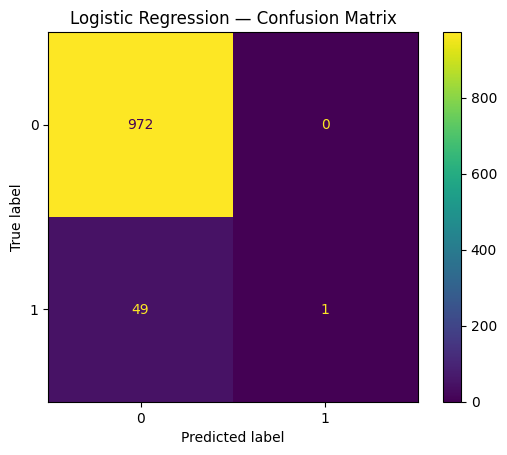

In [8]:
def get_metrics(model, Xtr, ytr, Xte, yte):
    """Fit model and return common binary-classification metrics on test data."""
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    if hasattr(model, "predict_proba"):
        score = model.predict_proba(Xte)[:, 1]
    else:
        score = model.decision_function(Xte)
    return {
        "Accuracy": accuracy_score(yte, pred),
        "Precision": precision_score(yte, pred, zero_division=0),
        "Recall": recall_score(yte, pred, zero_division=0),
        "F1": f1_score(yte, pred, zero_division=0),
        "ROC AUC": roc_auc_score(yte, score),
        "PR AUC (Average Precision)": average_precision_score(yte, score)
    }

dummy = DummyClassifier(strategy="most_frequent", random_state=SEED)
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
print("Majority-class baseline accuracy:", round(accuracy_score(y_test, dummy_pred), 4))

lr_default = LogisticRegression(max_iter=2000, random_state=SEED)
part1_metrics = get_metrics(lr_default, X_train_scaled, y_train, X_test_scaled, y_test)
print("\\nLogistic Regression metrics:")
display(pd.DataFrame([part1_metrics], index=["Logistic Regression"]).round(4))

lr_default.fit(X_train_scaled, y_train)
lr_pred = lr_default.predict(X_test_scaled)
cm = confusion_matrix(y_test, lr_pred)
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)
ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.title("Logistic Regression — Confusion Matrix")
plt.show()


### Part 1 interpretation
A majority-class model can achieve high accuracy by predicting “no stroke” for everyone, but it has zero recall for stroke cases. A false negative is a patient who had a stroke but was not flagged. For screening, examine recall, precision, F1, PR AUC, ROC AUC and the confusion matrix rather than relying on accuracy alone.

## Part 2 — Underfitting, Overfitting, Bias and Variance

### Task 2.1 — Validation curve

,max_depth,Train ROC AUC,CV ROC AUC mean,CV ROC AUC std
0,1,0.7171,0.7317,0.0158
1,2,0.8208,0.8168,0.0267
2,3,0.8375,0.8161,0.0288
3,4,0.8580,0.8180,0.0306
4,5,0.8758,0.7904,0.0322
5,6,0.9021,0.7503,0.0529
6,7,0.9286,0.7382,0.0535
7,8,0.9490,0.7215,0.0474
8,9,0.9674,0.6819,0.0429
9,10,0.9817,0.6444,0.0470


Best depth by mean CV ROC AUC: 4 | CV AUC: 0.818


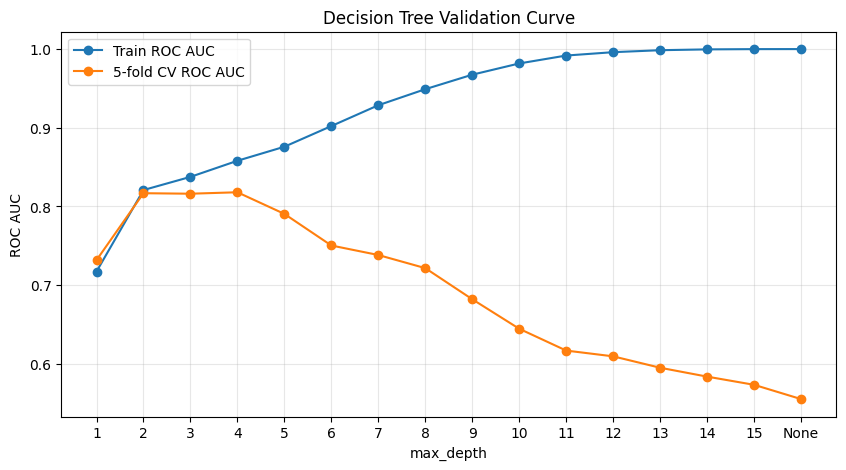

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
depths = list(range(1, 16)) + [None]
val_rows = []

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    tree.fit(X_train, y_train)
    train_auc = roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1])
    cv_auc_scores = cross_val_score(tree, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    val_rows.append({
        "max_depth": str(depth),
        "Train ROC AUC": train_auc,
        "CV ROC AUC mean": cv_auc_scores.mean(),
        "CV ROC AUC std": cv_auc_scores.std()
    })

validation_df = pd.DataFrame(val_rows)
display(validation_df.round(4))
best_row = validation_df.loc[validation_df["CV ROC AUC mean"].idxmax()]
print("Best depth by mean CV ROC AUC:", best_row["max_depth"],
      "| CV AUC:", round(best_row["CV ROC AUC mean"], 4))

xlabels = validation_df["max_depth"].tolist()
plt.figure(figsize=(10, 5))
plt.plot(xlabels, validation_df["Train ROC AUC"], marker="o", label="Train ROC AUC")
plt.plot(xlabels, validation_df["CV ROC AUC mean"], marker="o", label="5-fold CV ROC AUC")
plt.xlabel("max_depth")
plt.ylabel("ROC AUC")
plt.title("Decision Tree Validation Curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


### Task 2.2 — Learning curves

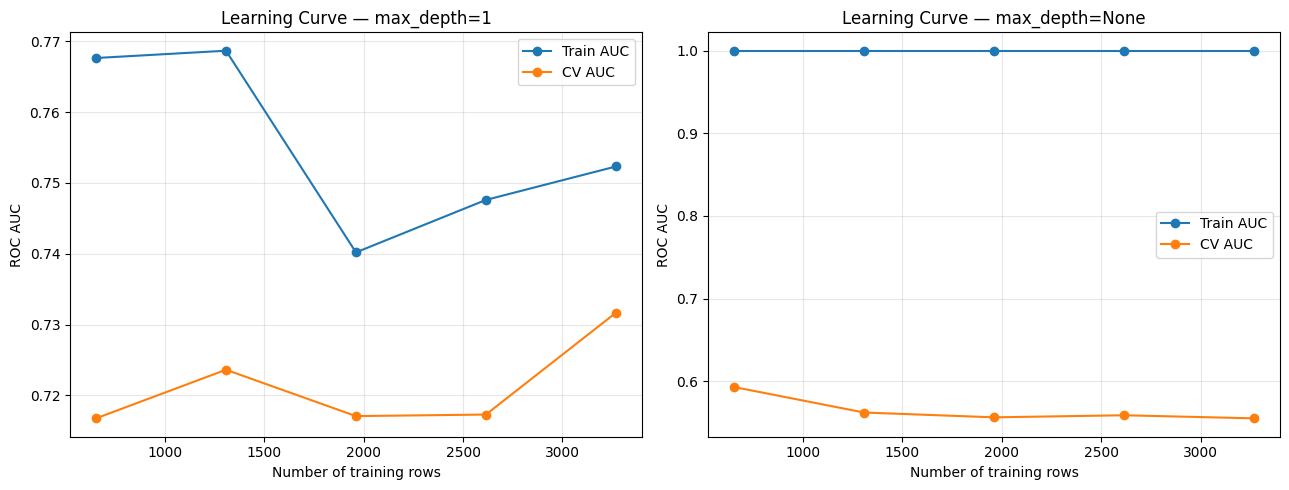

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, depth, title in zip(
    axes, [1, None], ["Learning Curve — max_depth=1", "Learning Curve — max_depth=None"]
):
    estimator = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    sizes, train_scores, valid_scores = learning_curve(
        estimator, X_train, y_train, cv=cv, scoring="roc_auc",
        train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1
    )
    ax.plot(sizes, train_scores.mean(axis=1), marker="o", label="Train AUC")
    ax.plot(sizes, valid_scores.mean(axis=1), marker="o", label="CV AUC")
    ax.set_xlabel("Number of training rows")
    ax.set_ylabel("ROC AUC")
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Task 2.3 — Direct variance measurement

In [11]:
rng = np.random.default_rng(SEED)
variance_rows = []
n_bootstrap = 40

for depth in [1, 3, None]:
    bootstrap_probabilities = []
    individual_auc = []
    for b in range(n_bootstrap):
        idx = rng.choice(len(X_train), size=len(X_train), replace=True)
        Xb = X_train.iloc[idx]
        yb = y_train.iloc[idx]
        tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED + b)
        tree.fit(Xb, yb)
        probs = tree.predict_proba(X_test)[:, 1]
        bootstrap_probabilities.append(probs)
        # AUC can fail only if test set has one class; stratified split should prevent that.
        individual_auc.append(roc_auc_score(y_test, probs))

    probs_array = np.asarray(bootstrap_probabilities)
    mean_probs = probs_array.mean(axis=0)
    variance_rows.append({
        "max_depth": str(depth),
        "Mean per-patient prediction variance": probs_array.var(axis=0).mean(),
        "Mean individual-tree test ROC AUC": np.mean(individual_auc),
        "ROC AUC of averaged probabilities": roc_auc_score(y_test, mean_probs)
    })

variance_df = pd.DataFrame(variance_rows)
display(variance_df.round(4))


,max_depth,Mean per-patient prediction variance,Mean individual-tree test ROC AUC,ROC AUC of averaged probabilities
0,1,0.0007,0.7623,0.8132
1,3,0.0017,0.7963,0.8339
2,None,0.0422,0.5526,0.7682


### Part 2 interpretation prompts
- **Validation curve:** identify a shallow depth with low train and CV AUC (underfitting), and a depth where train AUC is much higher than CV AUC (overfitting). Choose the depth with the best cross-validation AUC, considering stability too.
- **Learning curves:** high bias appears when train and CV scores are both poor and close together; high variance appears when train score is much higher than CV score. More data can help high variance, but may not fix a model that is too simple.
- **Variance table:** deeper trees typically vary more across bootstrap samples. Averaging probabilities often stabilizes predictions, which is related to how Random Forest averages many trees.
- **Bias–variance trade-off:** depth 1 is very simple and may have high bias; depth 3 is more flexible; an unlimited tree can fit complex patterns but may have high variance. Use your measured results to qualify these statements.

## Part 3 — ROC, Precision–Recall and Thresholds

### Task 3.1 — Compare models with curves

,ROC AUC,Average Precision (PR AUC)
Model,,
Logistic Regression,0.8393,0.2696
Decision Tree depth=3,0.7956,0.1621
Random Forest,0.8215,0.2183


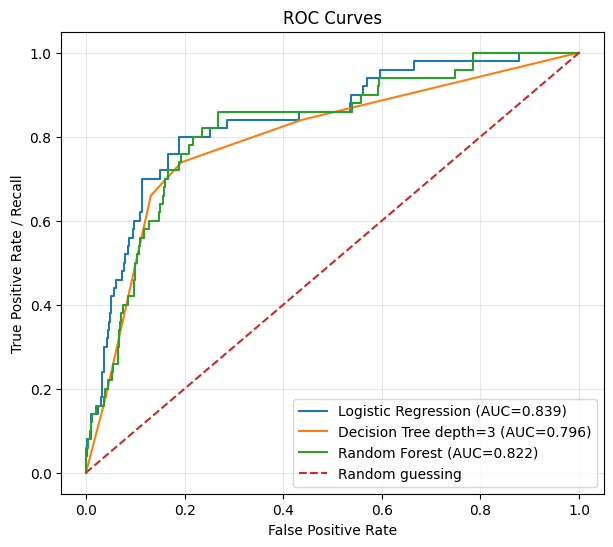

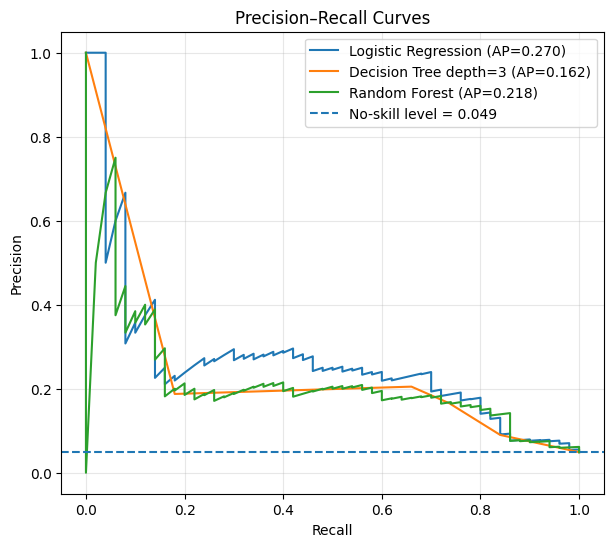

In [12]:
models = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=SEED), X_train_scaled, X_test_scaled),
    "Decision Tree depth=3": (DecisionTreeClassifier(max_depth=3, random_state=SEED), X_train, X_test),
    "Random Forest": (RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1
    ), X_train, X_test)
}
model_scores = {}
model_metrics = []

for name, (model, Xtr, Xte) in models.items():
    model.fit(Xtr, y_train)
    prob = model.predict_proba(Xte)[:, 1]
    model_scores[name] = prob
    model_metrics.append({
        "Model": name,
        "ROC AUC": roc_auc_score(y_test, prob),
        "Average Precision (PR AUC)": average_precision_score(y_test, prob)
    })
display(pd.DataFrame(model_metrics).set_index("Model").round(4))

plt.figure(figsize=(7, 6))
for name, prob in model_scores.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Recall")
plt.title("ROC Curves")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(7, 6))
stroke_rate = y_test.mean()
for name, prob in model_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")
plt.axhline(stroke_rate, linestyle="--", label=f"No-skill level = {stroke_rate:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


### Task 3.2 — Choose threshold from training data only

In [13]:
# Obtain out-of-fold probabilities using training data only.
lr_for_threshold = LogisticRegression(max_iter=2000, random_state=SEED)
oof_prob = cross_val_predict(
    lr_for_threshold, X_train_scaled, y_train, cv=cv,
    method="predict_proba", n_jobs=-1
)[:, 1]

threshold_candidates = np.unique(oof_prob)
valid_thresholds = []
for threshold in threshold_candidates:
    oof_pred = (oof_prob >= threshold).astype(int)
    rec = recall_score(y_train, oof_pred, zero_division=0)
    if rec >= 0.80:
        valid_thresholds.append(threshold)

if not valid_thresholds:
    chosen_threshold = 0.0
else:
    chosen_threshold = max(valid_thresholds)

print("Chosen threshold from OOF training probabilities:", round(float(chosen_threshold), 5))

lr_for_threshold.fit(X_train_scaled, y_train)
test_prob_threshold = lr_for_threshold.predict_proba(X_test_scaled)[:, 1]
test_pred_threshold = (test_prob_threshold >= chosen_threshold).astype(int)
threshold_cm = confusion_matrix(y_test, test_pred_threshold)
tn, fp, fn, tp = threshold_cm.ravel()

print("Test recall:", round(recall_score(y_test, test_pred_threshold, zero_division=0), 4))
print("Test precision:", round(precision_score(y_test, test_pred_threshold, zero_division=0), 4))
print("Confusion matrix [[TN, FP], [FN, TP]]:\\n", threshold_cm)
print("Patients flagged:", int(test_pred_threshold.sum()))
print("False alarms (false positives):", int(fp))


Chosen threshold from OOF training probabilities: 0.05068
Test recall: 0.82
Test precision: 0.1344
Confusion matrix [[TN, FP], [FN, TP]]:\n [[708 264]
 [  9  41]]
Patients flagged: 305
False alarms (false positives): 264


### Part 3 interpretation
ROC AUC measures how well the model ranks positive cases above negative cases across possible thresholds; it is not the recall at threshold 0.5. A model can rank cases reasonably well yet predict few positives at 0.5. For highly imbalanced data, the Precision–Recall curve is often more revealing because it focuses on positive-case precision and recall; compare its curve with the test stroke-rate no-skill line. A lower threshold may catch more strokes but usually creates more false alarms and reduces precision.

## Part 4 — Undersampling, Oversampling and SMOTE

### Task 4.1 — Compare methods (resample training rows only)

In [14]:
def evaluate_predictions(y_true, probs, threshold=0.5):
    pred = (probs >= threshold).astype(int)
    return {
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_true, probs),
        "PR AUC": average_precision_score(y_true, probs)
    }

resampling_methods = {
    "None": None,
    "class_weight=balanced": "class_weight",
    "Random undersampling": RandomUnderSampler(random_state=SEED),
    "Random oversampling": RandomOverSampler(random_state=SEED),
    "SMOTE": SMOTE(random_state=SEED)
}

comparison_rows = []
for model_name in ["Logistic Regression", "Random Forest"]:
    for method_name, sampler in resampling_methods.items():
        use_scaled = model_name == "Logistic Regression"
        Xtr = X_train_scaled if use_scaled else X_train
        Xte = X_test_scaled if use_scaled else X_test

        if model_name == "Logistic Regression":
            class_weight = "balanced" if sampler == "class_weight" else None
            model = LogisticRegression(max_iter=2000, random_state=SEED, class_weight=class_weight)
        else:
            class_weight = "balanced" if sampler == "class_weight" else None
            model = RandomForestClassifier(
                n_estimators=200, min_samples_leaf=5, random_state=SEED,
                n_jobs=-1, class_weight=class_weight
            )

        if sampler is not None and sampler != "class_weight":
            X_res, y_res = sampler.fit_resample(Xtr, y_train)
        else:
            X_res, y_res = Xtr, y_train

        model.fit(X_res, y_res)
        probs = model.predict_proba(Xte)[:, 1]
        metrics = evaluate_predictions(y_test, probs)
        comparison_rows.append({
            "Model": model_name,
            "Method": method_name,
            "Training rows after method": len(y_res),
            "Stroke cases after method": int(np.sum(y_res)),
            **metrics
        })

resampling_df = pd.DataFrame(comparison_rows)
display(resampling_df.round(4))


,Model,Method,Training rows after method,Stroke cases after method,Precision,Recall,F1,ROC AUC,PR AUC
0,Logistic Regression,None,4087,199,1.0000,0.02,0.0392,0.8393,0.2696
1,Logistic Regression,class_weight=balanced,4087,199,0.1347,0.80,0.2305,0.8396,0.2596
2,Logistic Regression,Random undersampling,398,199,0.1246,0.82,0.2164,0.8350,0.2333
3,Logistic Regression,Random oversampling,7776,3888,0.1333,0.80,0.2286,0.8385,0.2591
4,Logistic Regression,SMOTE,7776,3888,0.1347,0.80,0.2305,0.8407,0.2957
5,Random Forest,None,4087,199,0.0000,0.00,0.0000,0.8215,0.2183
6,Random Forest,class_weight=balanced,4087,199,0.1667,0.20,0.1818,0.8061,0.2045
7,Random Forest,Random undersampling,398,199,0.1032,0.84,0.1838,0.8132,0.1972
8,Random Forest,Random oversampling,7776,3888,0.1412,0.24,0.1778,0.8023,0.1837
9,Random Forest,SMOTE,7776,3888,0.6667,0.04,0.0755,0.8046,0.2424


### Task 4.2 — Demonstrate the wrong order (leakage)

In [15]:
# WRONG on purpose for demonstration only: SMOTE is applied before splitting.
# Do not use this result as a valid estimate of real-world performance.
X_all = X.copy()
y_all = y.copy()

# Reuse the numeric imputation/scaling already defined only for the correct split above.
# For this intentionally incorrect experiment, encode and impute all rows before SMOTE.
X_all_imp = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_all),
    columns=X_all.columns, index=X_all.index
)
X_smote_wrong, y_smote_wrong = SMOTE(random_state=SEED).fit_resample(X_all_imp, y_all)
Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    X_smote_wrong, y_smote_wrong, test_size=0.20, random_state=SEED, stratify=y_smote_wrong
)
rf_wrong = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1
)
rf_wrong.fit(Xw_train, yw_train)
wrong_probs = rf_wrong.predict_proba(Xw_test)[:, 1]
wrong_metrics = evaluate_predictions(yw_test, wrong_probs)

# Correct-order SMOTE result from original train-only split.
X_smote_correct, y_smote_correct = SMOTE(random_state=SEED).fit_resample(X_train, y_train)
rf_correct = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1
)
rf_correct.fit(X_smote_correct, y_smote_correct)
correct_probs = rf_correct.predict_proba(X_test)[:, 1]
correct_metrics = evaluate_predictions(y_test, correct_probs)

leakage_comparison = pd.DataFrame([
    {"Experiment": "Correct: split first, SMOTE train only", **correct_metrics},
    {"Experiment": "Wrong: SMOTE before split (illustration only)", **wrong_metrics}
])
display(leakage_comparison.round(4))
print("Note: the wrong-order experiment evaluates on a synthetic, rebalanced test set and is not comparable to the untouched real test set.")


,Experiment,Precision,Recall,F1,ROC AUC,PR AUC
0,"Correct: split first, SMOTE train only",0.6667,0.0400,0.0755,0.8046,0.2424
1,Wrong: SMOTE before split (illustration only),0.9978,0.9506,0.9737,0.9952,0.9960


Note: the wrong-order experiment evaluates on a synthetic, rebalanced test set and is not comparable to the untouched real test set.


### Part 4 interpretation
Resampling changes the training class balance, which can change the model's decision boundary and often increases recall while reducing precision. ROC AUC may change less because it evaluates ranking across thresholds. Logistic Regression and Random Forest need not react identically because they learn patterns differently. SMOTE before splitting leaks information: synthetic examples are made using the full dataset, so test-derived information can influence training, and the test set is no longer the untouched real-world distribution. Choose a method based on the measured recall, precision, false alarms and practical costs.

## Part 5 — Noisy Data

### Task 5.1 — Label noise

Model,Decision Tree depth=3,Decision Tree unlimited,Logistic Regression,Random Forest
Noise fraction,,,,
0.00,0.7956,0.5722,0.8393,0.8215
0.05,0.8022,0.5376,0.8248,0.7905
0.10,0.7903,0.5420,0.8225,0.7548
0.20,0.7439,0.5050,0.7968,0.6764


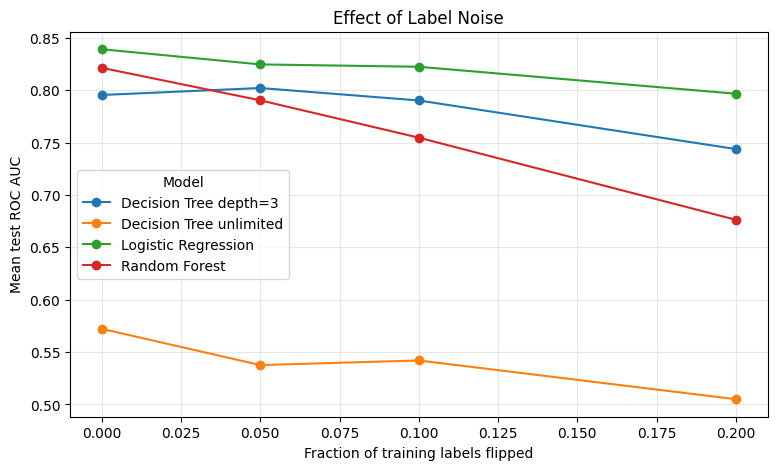

In [16]:
def flip_labels(y_values, fraction, rng):
    y_noisy = np.asarray(y_values).copy()
    n_flip = int(round(fraction * len(y_noisy)))
    if n_flip > 0:
        positions = rng.choice(len(y_noisy), size=n_flip, replace=False)
        y_noisy[positions] = 1 - y_noisy[positions]
    return y_noisy

def make_models(seed):
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000, random_state=seed),
        "Decision Tree depth=3": DecisionTreeClassifier(max_depth=3, random_state=seed),
        "Decision Tree unlimited": DecisionTreeClassifier(max_depth=None, random_state=seed),
        "Random Forest": RandomForestClassifier(
            n_estimators=200, min_samples_leaf=5, random_state=seed, n_jobs=-1
        )
    }

label_noise_levels = [0, 0.05, 0.10, 0.20]
label_noise_records = []
for noise_fraction in label_noise_levels:
    repeats = 1 if noise_fraction == 0 else 5
    for repeat in range(repeats):
        rng_noise = np.random.default_rng(SEED + 1000 * int(noise_fraction * 100) + repeat)
        y_train_noisy = y_train.copy() if noise_fraction == 0 else flip_labels(y_train, noise_fraction, rng_noise)
        for model_name, model in make_models(SEED + repeat).items():
            if model_name == "Logistic Regression":
                model.fit(X_train_scaled, y_train_noisy)
                probs = model.predict_proba(X_test_scaled)[:, 1]
            else:
                model.fit(X_train, y_train_noisy)
                probs = model.predict_proba(X_test)[:, 1]
            label_noise_records.append({
                "Noise fraction": noise_fraction,
                "Repeat": repeat + 1,
                "Model": model_name,
                "Test ROC AUC": roc_auc_score(y_test, probs)
            })

label_noise_df = pd.DataFrame(label_noise_records)
label_noise_summary = label_noise_df.groupby(["Noise fraction", "Model"])["Test ROC AUC"].mean().unstack()
display(label_noise_summary.round(4))
label_noise_summary.plot(marker="o", figsize=(9, 5))
plt.xlabel("Fraction of training labels flipped")
plt.ylabel("Mean test ROC AUC")
plt.title("Effect of Label Noise")
plt.grid(True, alpha=0.3)
plt.show()


### Task 5.2 — Feature noise

Model,Decision Tree depth=3,Decision Tree unlimited,Logistic Regression,Random Forest
Noise level,,,,
0.0,0.7956,0.5643,0.8393,0.8202
0.5,0.7870,0.5448,0.8335,0.8002
1.0,0.7628,0.5211,0.8082,0.7811
2.0,0.6917,0.5173,0.7678,0.7246


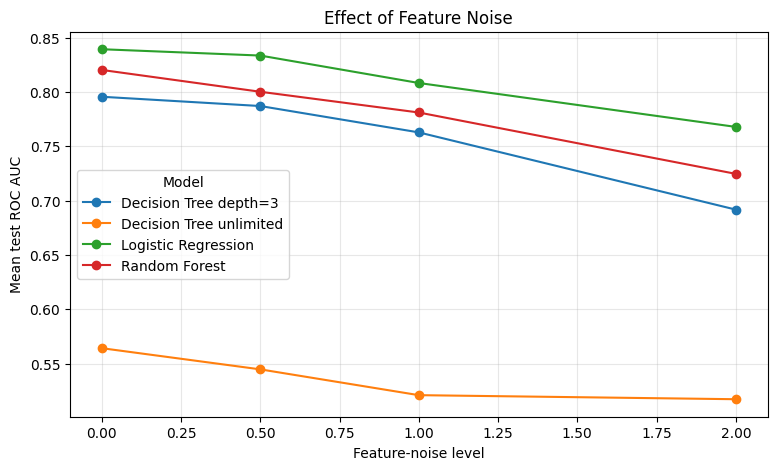

In [17]:
numeric_noise_cols = [c for c in ["age", "avg_glucose_level", "bmi"] if c in X_train.columns]
feature_noise_levels = [0, 0.5, 1, 2]
feature_noise_records = []

for noise_level in feature_noise_levels:
    repeats = 1 if noise_level == 0 else 5
    for repeat in range(repeats):
        rng_noise = np.random.default_rng(SEED + 2000 * int(noise_level * 10) + repeat)
        X_train_noisy = X_train.copy()
        for col in numeric_noise_cols:
            col_std = X_train[col].std()
            X_train_noisy[col] = X_train[col].to_numpy() + (
                rng_noise.normal(size=len(X_train)) * col_std * noise_level
            )

        # Fit scaler on the noisy training data for Logistic Regression, as required by the manual.
        noisy_scaler = StandardScaler()
        X_train_noisy_scaled = pd.DataFrame(
            noisy_scaler.fit_transform(X_train_noisy),
            columns=X_train.columns, index=X_train.index
        )
        X_test_scaled_for_noise = pd.DataFrame(
            noisy_scaler.transform(X_test),
            columns=X_test.columns, index=X_test.index
        )

        for model_name, model in make_models(SEED + repeat + 300).items():
            if model_name == "Logistic Regression":
                model.fit(X_train_noisy_scaled, y_train)
                probs = model.predict_proba(X_test_scaled_for_noise)[:, 1]
            else:
                model.fit(X_train_noisy, y_train)
                probs = model.predict_proba(X_test)[:, 1]
            feature_noise_records.append({
                "Noise level": noise_level,
                "Repeat": repeat + 1,
                "Model": model_name,
                "Test ROC AUC": roc_auc_score(y_test, probs)
            })

feature_noise_df = pd.DataFrame(feature_noise_records)
feature_noise_summary = feature_noise_df.groupby(["Noise level", "Model"])["Test ROC AUC"].mean().unstack()
display(feature_noise_summary.round(4))
feature_noise_summary.plot(marker="o", figsize=(9, 5))
plt.xlabel("Feature-noise level")
plt.ylabel("Mean test ROC AUC")
plt.title("Effect of Feature Noise")
plt.grid(True, alpha=0.3)
plt.show()


### Task 5.3 — SMOTE with noisy labels

In [18]:
smote_noise_rows = []
for repeat in range(3):
    y_noisy = flip_labels(y_train, 0.10, np.random.default_rng(SEED + 500 + repeat))
    for model_name in ["Logistic Regression", "Random Forest"]:
        for use_smote in [False, True]:
            if model_name == "Logistic Regression":
                Xtr, Xte = X_train_scaled, X_test_scaled
                model = LogisticRegression(max_iter=2000, random_state=SEED + repeat)
            else:
                Xtr, Xte = X_train, X_test
                model = RandomForestClassifier(
                    n_estimators=200, min_samples_leaf=5, random_state=SEED + repeat, n_jobs=-1
                )

            if use_smote:
                X_fit, y_fit = SMOTE(random_state=SEED + repeat).fit_resample(Xtr, y_noisy)
            else:
                X_fit, y_fit = Xtr, y_noisy

            model.fit(X_fit, y_fit)
            probs = model.predict_proba(Xte)[:, 1]
            smote_noise_rows.append({
                "Repeat": repeat + 1,
                "Model": model_name,
                "SMOTE": "Yes" if use_smote else "No",
                "ROC AUC": roc_auc_score(y_test, probs),
                "PR AUC": average_precision_score(y_test, probs)
            })

smote_noise_df = pd.DataFrame(smote_noise_rows)
display(smote_noise_df.groupby(["Model", "SMOTE"])[["ROC AUC", "PR AUC"]].mean().round(4))


ROC AUC  PR AUC
Model               SMOTE                 
Logistic Regression No      0.8268  0.2830
                    Yes     0.8137  0.2715
Random Forest       No      0.7476  0.1627
                    Yes     0.6898  0.1372

### Part 5 interpretation
Use the highest-noise row/level in your tables to identify the most affected model and the most stable model. Compare label noise and feature noise based on your own results rather than assuming one always causes more damage. SMOTE creates synthetic minority examples based on labelled neighbours; if some minority labels are wrong, it can create additional synthetic examples around misleading patterns, potentially amplifying the damage.

## Part 6 — Final Decision and Conclusion

In [19]:
# Example final approach: Logistic Regression with the training-only threshold selected in Part 3.
# Compare it with the default 0.5 threshold on the same untouched test set.
final_lr = LogisticRegression(max_iter=2000, random_state=SEED)
final_lr.fit(X_train_scaled, y_train)
final_prob = final_lr.predict_proba(X_test_scaled)[:, 1]

def final_threshold_row(label, threshold, probs, y_true):
    pred = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "Approach": label,
        "Threshold": threshold,
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "False alarms (FP)": int(fp),
        "Missed strokes (FN)": int(fn),
        "Patients flagged": int(pred.sum())
    }

final_comparison = pd.DataFrame([
    final_threshold_row("Default threshold", 0.5, final_prob, y_test),
    final_threshold_row("Training-OOF chosen threshold", chosen_threshold, final_prob, y_test)
])
display(final_comparison.round(4))


,Approach,Threshold,Precision,Recall,F1,False alarms (FP),Missed strokes (FN),Patients flagged
0,Default threshold,0.5000,1.0000,0.02,0.0392,0,49,1
1,Training-OOF chosen threshold,0.0507,0.1344,0.82,0.2310,264,9,305


### Executive Summary (complete with your generated numbers)
1. I selected **[model and threshold/resampling method]** because it offered a useful balance for a stroke-screening task.
2. On the untouched test set, its recall was **[value]** and precision was **[value]**.
3. It flagged **[value]** patients, including **[value]** false alarms, and missed **[value]** stroke cases.
4. Compared with threshold 0.5, the selected approach **[describe measured change in recall and precision]**.
5. I avoided data leakage by fitting the imputer and scaler on training data only, and applying resampling only to training rows.
6. The test set was not used to choose the threshold.
7. A limitation is that the test set contains relatively few stroke cases, so estimates can vary; the threshold also depends on the hospital's acceptable false-alarm cost.

